# Misión 3: Predicción de Tiempo de Entrega
**Olist Brazilian E-Commerce**

Objetivo: predecir cuántos días tardará una entrega, usando características
del pedido (distancia, precio, flete) y del vendedor/comprador.

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.pipeline import Pipeline

In [11]:
from pathlib import Path
DATA_PATH = Path('Datasets')

orders = pd.read_csv(DATA_PATH / 'olist_orders_dataset.csv')
order_items = pd.read_csv(DATA_PATH / 'olist_order_items_dataset.csv')
customers = pd.read_csv(DATA_PATH / 'olist_customers_dataset.csv')
sellers = pd.read_csv(DATA_PATH / 'olist_sellers_dataset.csv')
geolocations = pd.read_csv(DATA_PATH / 'olist_geolocation_dataset.csv')

print("Datos cargados:")
print(f"  orders:      {orders.shape}")
print(f"  order_items: {order_items.shape}")
print(f"  customers:   {customers.shape}")
print(f"  sellers:     {sellers.shape}")
print(f"  geolocations:{geolocations.shape}")

Datos cargados:
  orders:      (99441, 8)
  order_items: (112650, 7)
  customers:   (99441, 5)
  sellers:     (3095, 4)
  geolocations:(1000163, 5)


In [12]:
# Convertir fechas
orders['order_purchase_timestamp'] = pd.to_datetime(orders['order_purchase_timestamp'])
orders['order_delivered_customer_date'] = pd.to_datetime(orders['order_delivered_customer_date'])

# solo me interesan los pedidos que llegaron
orders_delivered = orders[orders['order_status'] == 'delivered'].copy()

# Variable objetivo: días reales de entrega
orders_delivered['delivery_days'] = (
    orders_delivered['order_delivered_customer_date'] -
    orders_delivered['order_purchase_timestamp']
).dt.days

# sacar nulos y entregas negativas (errores de datos)
orders_delivered = orders_delivered.dropna(subset=['delivery_days'])
orders_delivered = orders_delivered[orders_delivered['delivery_days'] > 0]

print(f"Pedidos entregados: {len(orders_delivered)}")
print(f"Días de entrega — media: {orders_delivered['delivery_days'].mean():.1f}, mediana: {orders_delivered['delivery_days'].median():.1f}")

Pedidos entregados: 96457
Días de entrega — media: 12.1, mediana: 10.0


In [13]:
# Coordenadas promedio por código postal
geo_mean = geolocations.groupby('geolocation_zip_code_prefix').agg(
    lat=('geolocation_lat', 'mean'),
    lng=('geolocation_lng', 'mean')
).reset_index()

# Unir coordenadas de clientes
customers_geo = customers.merge(geo_mean, left_on='customer_zip_code_prefix', right_on='geolocation_zip_code_prefix', how='left')
customers_geo = customers_geo[['customer_id', 'lat', 'lng']].rename(columns={'lat': 'cust_lat', 'lng': 'cust_lng'})

# Unir coordenadas de vendedores
sellers_geo = sellers.merge(geo_mean, left_on='seller_zip_code_prefix', right_on='geolocation_zip_code_prefix', how='left')
sellers_geo = sellers_geo[['seller_id', 'lat', 'lng']].rename(columns={'lat': 'sell_lat', 'lng': 'sell_lng'})

# Función Haversine — distancia real en km
def haversine(lat1, lng1, lat2, lng2):
    R = 6371  # radio de la tierra en km
    # convertir grados a radianes
    lat1 = np.radians(lat1)
    lng1 = np.radians(lng1)
    lat2 = np.radians(lat2)
    lng2 = np.radians(lng2)
    dlat = lat2 - lat1
    dlng = lng2 - lng1
    a = np.sin(dlat/2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlng/2)**2
    distancia = 2 * R * np.arcsin(np.sqrt(a))
    return distancia

# prueba rápida: São Paulo a Rio de Janeiro debería ser ~360 km
print(haversine(-23.5, -46.6, -22.9, -43.1))

363.86869962300653


In [14]:
# Unir todo en un solo DataFrame
df = orders_delivered[['order_id', 'customer_id', 'order_purchase_timestamp', 'delivery_days']].copy()
# unir precio y flete del pedido
df = df.merge(order_items[['order_id', 'seller_id', 'price', 'freight_value']], on='order_id', how='left')
df = df.merge(customers_geo, on='customer_id', how='left')
df = df.merge(sellers_geo, on='seller_id', how='left')

# Calcular distancia
df['distance_km'] = haversine(df['cust_lat'], df['cust_lng'], df['sell_lat'], df['sell_lng'])

# el mes puede influir en los tiempos (diciembre, etc.)
df['purchase_month'] = df['order_purchase_timestamp'].dt.month

# Eliminar nulos
df = df.dropna(subset=['distance_km', 'price', 'freight_value', 'delivery_days'])

print(f"Dataset final: {df.shape}")
print(df[['price', 'freight_value', 'distance_km', 'purchase_month', 'delivery_days']].describe().round(2))

Dataset final: (109635, 13)
           price  freight_value  distance_km  purchase_month  delivery_days
count  109635.00      109635.00    109635.00       109635.00      109635.00
mean      120.01          19.94       596.28            6.03          12.00
std       182.50          15.71       588.56            3.23           9.45
min         0.85           0.00         0.00            1.00           1.00
25%        39.90          13.07       185.56            3.00           6.00
50%        74.90          16.25       431.94            6.00          10.00
75%       134.50          21.15       791.63            8.00          15.00
max      6735.00         409.68      8677.91           12.00         209.00


In [7]:
# ordeno por fecha antes de splitear para no mezclar datos futuros con pasados
df_sorted = df.sort_values('order_purchase_timestamp')

features = ['price', 'freight_value', 'distance_km', 'purchase_month']
X = df_sorted[features]
y = df_sorted['delivery_days']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

print(f"Train: {X_train.shape[0]} muestras | Test: {X_test.shape[0]} muestras")

# cada modelo va dentro de un Pipeline con su propio scaler
modelos = {
    'Linear Regression': Pipeline([('scaler', StandardScaler()), ('model', LinearRegression())]),
    'Decision Tree':     Pipeline([('scaler', StandardScaler()), ('model', DecisionTreeRegressor(max_depth=5, random_state=42))]),
    'Random Forest':     Pipeline([('scaler', StandardScaler()), ('model', RandomForestRegressor(n_estimators=100, max_depth=6, random_state=42))]),
    'Gradient Boosting': Pipeline([('scaler', StandardScaler()), ('model', GradientBoostingRegressor(n_estimators=100, random_state=42))]),
}

resultados = {}
for nombre, pipe in modelos.items():
    pipe.fit(X_train, y_train)
    y_pred_train = pipe.predict(X_train)
    y_pred_test  = pipe.predict(X_test)
    resultados[nombre] = {
        'MAE':       mean_absolute_error(y_test, y_pred_test),
        'R2':        r2_score(y_test, y_pred_test),
        'MAE_train': mean_absolute_error(y_train, y_pred_train)
    }

print(f"{'Modelo':<25} {'MAE Train':>10} {'MAE Test':>10} {'R²':>8}")
print("-" * 55)
for nombre, metricas in resultados.items():
    ovfit = " ← overfitting" if (metricas['MAE_train'] < metricas['MAE'] * 0.7) else ""
    print(f"{nombre:<25} {metricas['MAE_train']:>10.2f} {metricas['MAE']:>10.2f} {metricas['R2']:>8.4f}{ovfit}")


Train: 87708 muestras | Test: 21927 muestras
Modelo                      MAE Train   MAE Test       R²
-------------------------------------------------------
Linear Regression               5.83       5.80  -0.4454
Decision Tree                   5.51       4.60  -0.0196
Random Forest                   5.43       4.51  -0.0023
Gradient Boosting               5.41       4.45   0.0057

Verificación con Pipeline (Gradient Boosting):
  MAE: 4.45

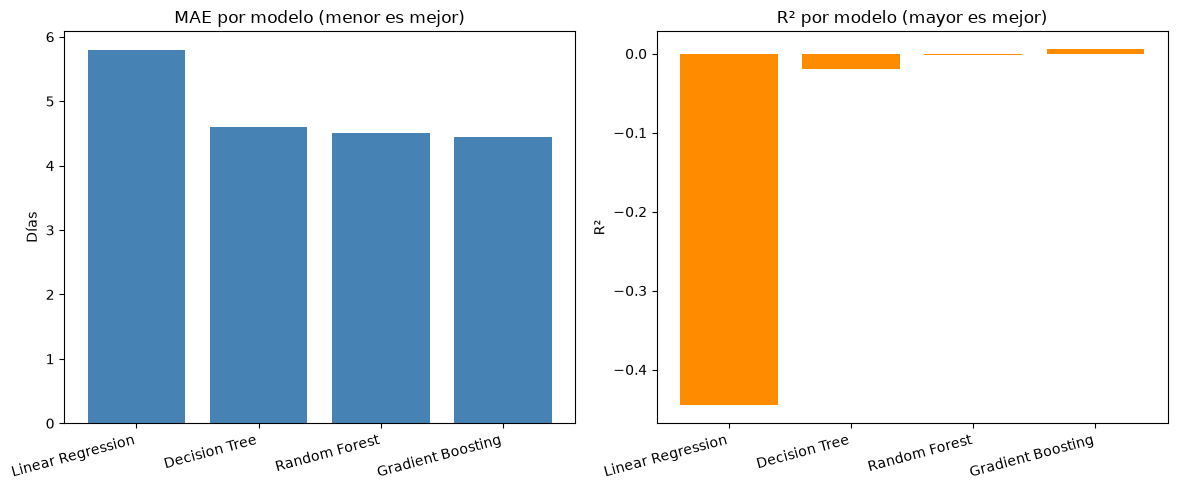

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

nombres = list(resultados.keys())
maes = [resultados[n]['MAE'] for n in nombres]
r2s  = [resultados[n]['R2']  for n in nombres]

x = range(len(nombres))

axes[0].bar(x, maes, color='steelblue')
axes[0].set_title('MAE por modelo (menor es mejor)')
axes[0].set_ylabel('Días')
axes[0].set_xticks(x)
axes[0].set_xticklabels(nombres, rotation=15, ha='right')

axes[1].bar(x, r2s, color='darkorange')
axes[1].set_title('R² por modelo (mayor es mejor)')
axes[1].set_ylabel('R²')
axes[1].set_xticks(x)
axes[1].set_xticklabels(nombres, rotation=15, ha='right')

plt.tight_layout()
plt.show()

## Conclusiones

| Modelo | MAE Train | MAE Test | R² |
|---|---|---|---|
| Linear Regression | 5.83 | 5.80 | -0.45 |
| Decision Tree | 5.51 | 4.60 | -0.02 |
| Random Forest | 5.43 | 4.51 | 0.00 |
| **Gradient Boosting** | **5.41** | **4.45** | **0.01** |

**Overfitting/Underfitting:**
- Ningún modelo overfittea — el MAE en train es similar al test en todos los casos
- Linear Regression underfittea claramente — R² negativo indica que no captura los patrones
- Gradient Boosting es el más equilibrado

**Por qué Gradient Boosting:**
El modelo va corrigiendo los errores del árbol anterior en cada paso. También probé con Pipeline que da el mismo resultado y deja el código más ordenado. El R² quedó bajo (0.01) pero creo que es porque faltan datos importantes como el operador logístico o si había stock disponible.

**Features adicionales que podrían mejorar el R²:**
- **Categoría del producto**: electrónica vs. ropa tienen tiempos de procesamiento distintos.
- **Día de la semana de la compra**: los pedidos del viernes o fin de semana salen más tarde.
- **Estado del vendedor y del comprador**: la distancia en km no captura la calidad de la infraestructura logística de cada estado (São Paulo vs. Amazonas, por ejemplo).